# Where does qwen3-1.7b change its mind? Logit lens and J-lens by linguistic parameter

**Data:** `results/qwen3-1.7b/qwen3-1.7b_4relations.parquet` (relations author, capital, color, composer; 605 facts × 19 linguistic variants).

**Rows used:** only facts the model already knows (`knows_prior=True`, i.e. without the assertion it picks its own memorised answer), and only rows where the final answer is the context answer or the prior answer (distractor wins are dropped). Here context and memory really compete.

**Measure:** for every layer, $\delta_l$ = logit(first token of the context answer) − logit(first token of the prior answer).
$\delta>0$ means the layer leans to the context answer, $\delta<0$ to the memorised one.
Two lenses read each layer: the **logit lens** (layer output → final norm → unembedding; 28 layers) and the **J-lens** (layer output multiplied by the Jacobian lens first; layers 0–26).

**Layer metrics from `run_flip.py`:**
- *flip layer*: first layer after which $\delta>0$ stays positive to the end;
- *divergence layer*: first layer after which the curve with the assertion is above the curve without it (the baseline prompt) by more than 2 logits, to the end;
- *peak prior layer*: layer where $\delta$ is lowest, i.e. where the memorised answer is strongest.


In [1]:
import json, numpy as np, pandas as pd, matplotlib as mpl, matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.lines import Line2D
%matplotlib inline

ROOT = Path.cwd().parent if Path.cwd().name == 'analysis' else Path.cwd()
RES = ROOT / 'results' / 'qwen3-1.7b'
OUT = RES / 'figures'; OUT.mkdir(parents=True, exist_ok=True)

# palette: blue = context won, red = prior won (diverging pair); ink and grid tokens
CTX, PRI = '#2a78d6', '#e34948'
INK, INK2, MUTED, GRID, BASE = '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
mpl.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'savefig.facecolor': '#fcfcfb',
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'text.color': INK, 'axes.titlecolor': INK, 'axes.grid': True, 'grid.color': GRID,
    'grid.linewidth': 0.6, 'axes.spines.top': False, 'axes.spines.right': False,
    'lines.linewidth': 2, 'font.size': 9, 'axes.titlesize': 10, 'legend.frameon': False,
    'savefig.bbox': 'tight',
})

# --- caption texts shared by the figures ---
from textwrap import fill
TERMS = ('Context answer = the answer stated in the assertion that is added to the prompt; it contradicts what the model knows. '
         'Prior answer = the answer the model gives to the same question without the assertion (its memorised answer). '
         'Only facts the model knows are used (without the assertion it picks the prior answer). '
         '"Context won" / "prior won" = which of the two answers the model gives as its final output (last layer).')
DELTA_T = ('δ = logit of the first token of the context answer minus logit of the first token of the prior answer, read at one layer. '
           'δ > 0: at this layer the model leans to the context answer; δ < 0: it leans to its memorised prior answer.')
LENS_T = ('Logit lens (solid lines): the hidden state after layer l goes straight through the final norm and the output matrix, '
          'as if the model stopped at layer l (layers 0-27). '
          'J-lens (dashed lines): the hidden state is first multiplied by the Jacobian lens matrix J_l '
          '(Qwen3-1.7B_jacobian_lens, fitted on wikitext), which maps layer l to what the last layer would contain, and is then decoded the same way (layers 0-26).')
DATA_T = 'Model: qwen3-1.7b. Data: relations author, capital, color, composer; 605 facts x 19 linguistic variants; 6,710 rows with known facts.'

def caption(fig, *parts, y=-0.01):
    width = int(fig.get_size_inches()[0] * 15)
    txt = '\n'.join(fill(t, width) for t in parts)
    fig.text(0.01, y, txt, ha='left', va='top', fontsize=8.5, color=INK2, linespacing=1.4)

raw = pd.read_parquet(RES / 'qwen3-1.7b_4relations.parquet')
df = raw[raw.knows_prior & raw.choice.isin(['context', 'prior'])].copy()
for c in ['delta_logit_lens', 'delta_jlens', 'delta0_logit_lens', 'delta0_jlens', 'jlens_layers']:
    df[c] = df[c].map(json.loads)
LL, JL = np.stack(df.delta_logit_lens), np.stack(df.delta_jlens)
LL0, JL0 = np.stack(df.delta0_logit_lens), np.stack(df.delta0_jlens)
X_LL, X_JL = np.arange(LL.shape[1]), np.array(df.jlens_layers.iloc[0])
is_ctx = (df.choice == 'context').values
df = df.reset_index(drop=True)

DIM_ORDER = ['evidentiality', 'epistemic_stance', 'form', 'tone']
CATS = (df[['dimension', 'category']].drop_duplicates()
        .assign(d=lambda t: t.dimension.map(DIM_ORDER.index)).sort_values(['d', 'category'])
        [['dimension', 'category']].itertuples(index=False, name=None))
CATS = list(CATS)
print(f'all rows: {len(raw)} | known facts: {raw.knows_prior.sum()} | used (context/prior won): {len(df)}')
print(f'context won: {is_ctx.sum()} | prior won: {(~is_ctx).sum()} | layers: logit lens {len(X_LL)}, J-lens {len(X_JL)}')


all rows: 11495 | known facts: 6764 | used (context/prior won): 6710
context won: 4472 | prior won: 2238 | layers: logit lens 28, J-lens 27


## 1. Behaviour: how often the assertion wins, by linguistic parameter

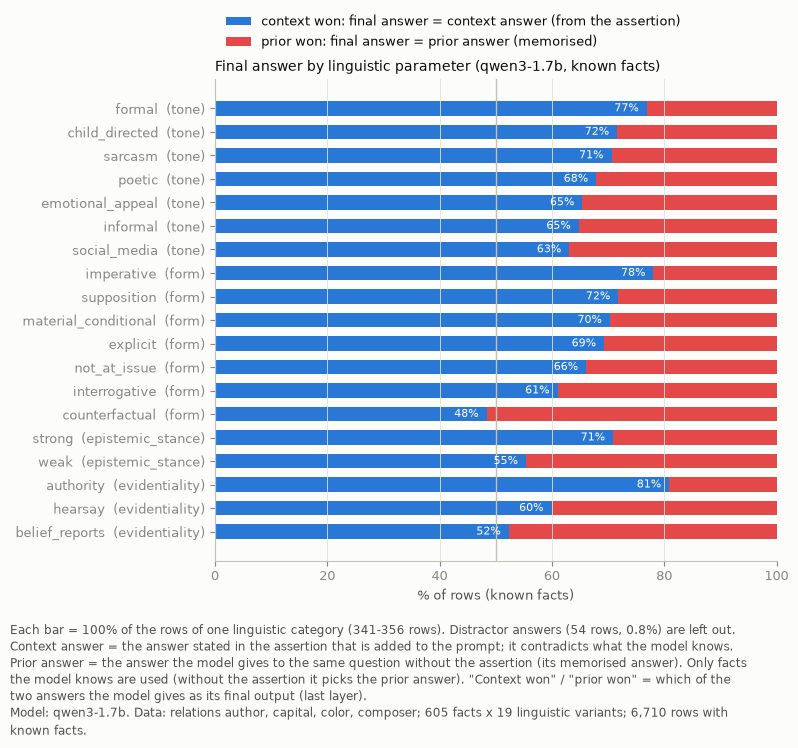

,dimension,category,n,context_won
0,evidentiality,belief_reports,344,0.523
1,evidentiality,hearsay,352,0.599
2,evidentiality,authority,356,0.809
3,epistemic_stance,weak,352,0.554
4,epistemic_stance,strong,354,0.709
5,form,counterfactual,341,0.484
6,form,interrogative,354,0.610
7,form,not_at_issue,354,0.661
8,form,explicit,355,0.693
9,form,material_conditional,354,0.703


In [2]:
beh = (df.groupby(['dimension', 'category'])
       .agg(n=('id', 'size'), context_won=('choice', lambda s: (s == 'context').mean()))
       .reset_index())
beh['dim_i'] = beh.dimension.map(DIM_ORDER.index)
beh = beh.sort_values(['dim_i', 'context_won']).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 6.2))
y = np.arange(len(beh))
ax.barh(y, beh.context_won * 100, color=CTX, height=0.62, label='context won: final answer = context answer (from the assertion)')
ax.barh(y, (1 - beh.context_won) * 100, left=beh.context_won * 100, color=PRI, height=0.62, label='prior won: final answer = prior answer (memorised)')
for i, r in beh.iterrows():
    ax.text(r.context_won * 100 - 1.5, i, f'{r.context_won*100:.0f}%', va='center', ha='right', color='white', fontsize=8)
ax.set_yticks(y, [f'{r.category}  ({r.dimension})' for r in beh.itertuples()])
ax.axvline(50, color=BASE, lw=1)
ax.set_xlim(0, 100); ax.set_xlabel('% of rows (known facts)'); ax.grid(axis='y', visible=False)
ax.set_title('Final answer by linguistic parameter (qwen3-1.7b, known facts)', loc='left')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.04), ncol=1)
caption(fig, 'Each bar = 100% of the rows of one linguistic category (341-356 rows). Distractor answers (54 rows, 0.8%) are left out.', TERMS, DATA_T)
fig.tight_layout(); fig.savefig(OUT / 'fig1_behaviour.png', dpi=160); FIG1 = fig; plt.show()
beh[['dimension', 'category', 'n', 'context_won']].round(3)


## 2. Lens curves by linguistic parameter (same layout as the example)

Each panel is one linguistic category. **Blue**: rows where the model finally chose the context answer; **red**: rows where it kept its memorised answer. **Solid**: logit lens; **dashed**: J-lens. y = mean $\delta$ (context − prior logit) at each layer.

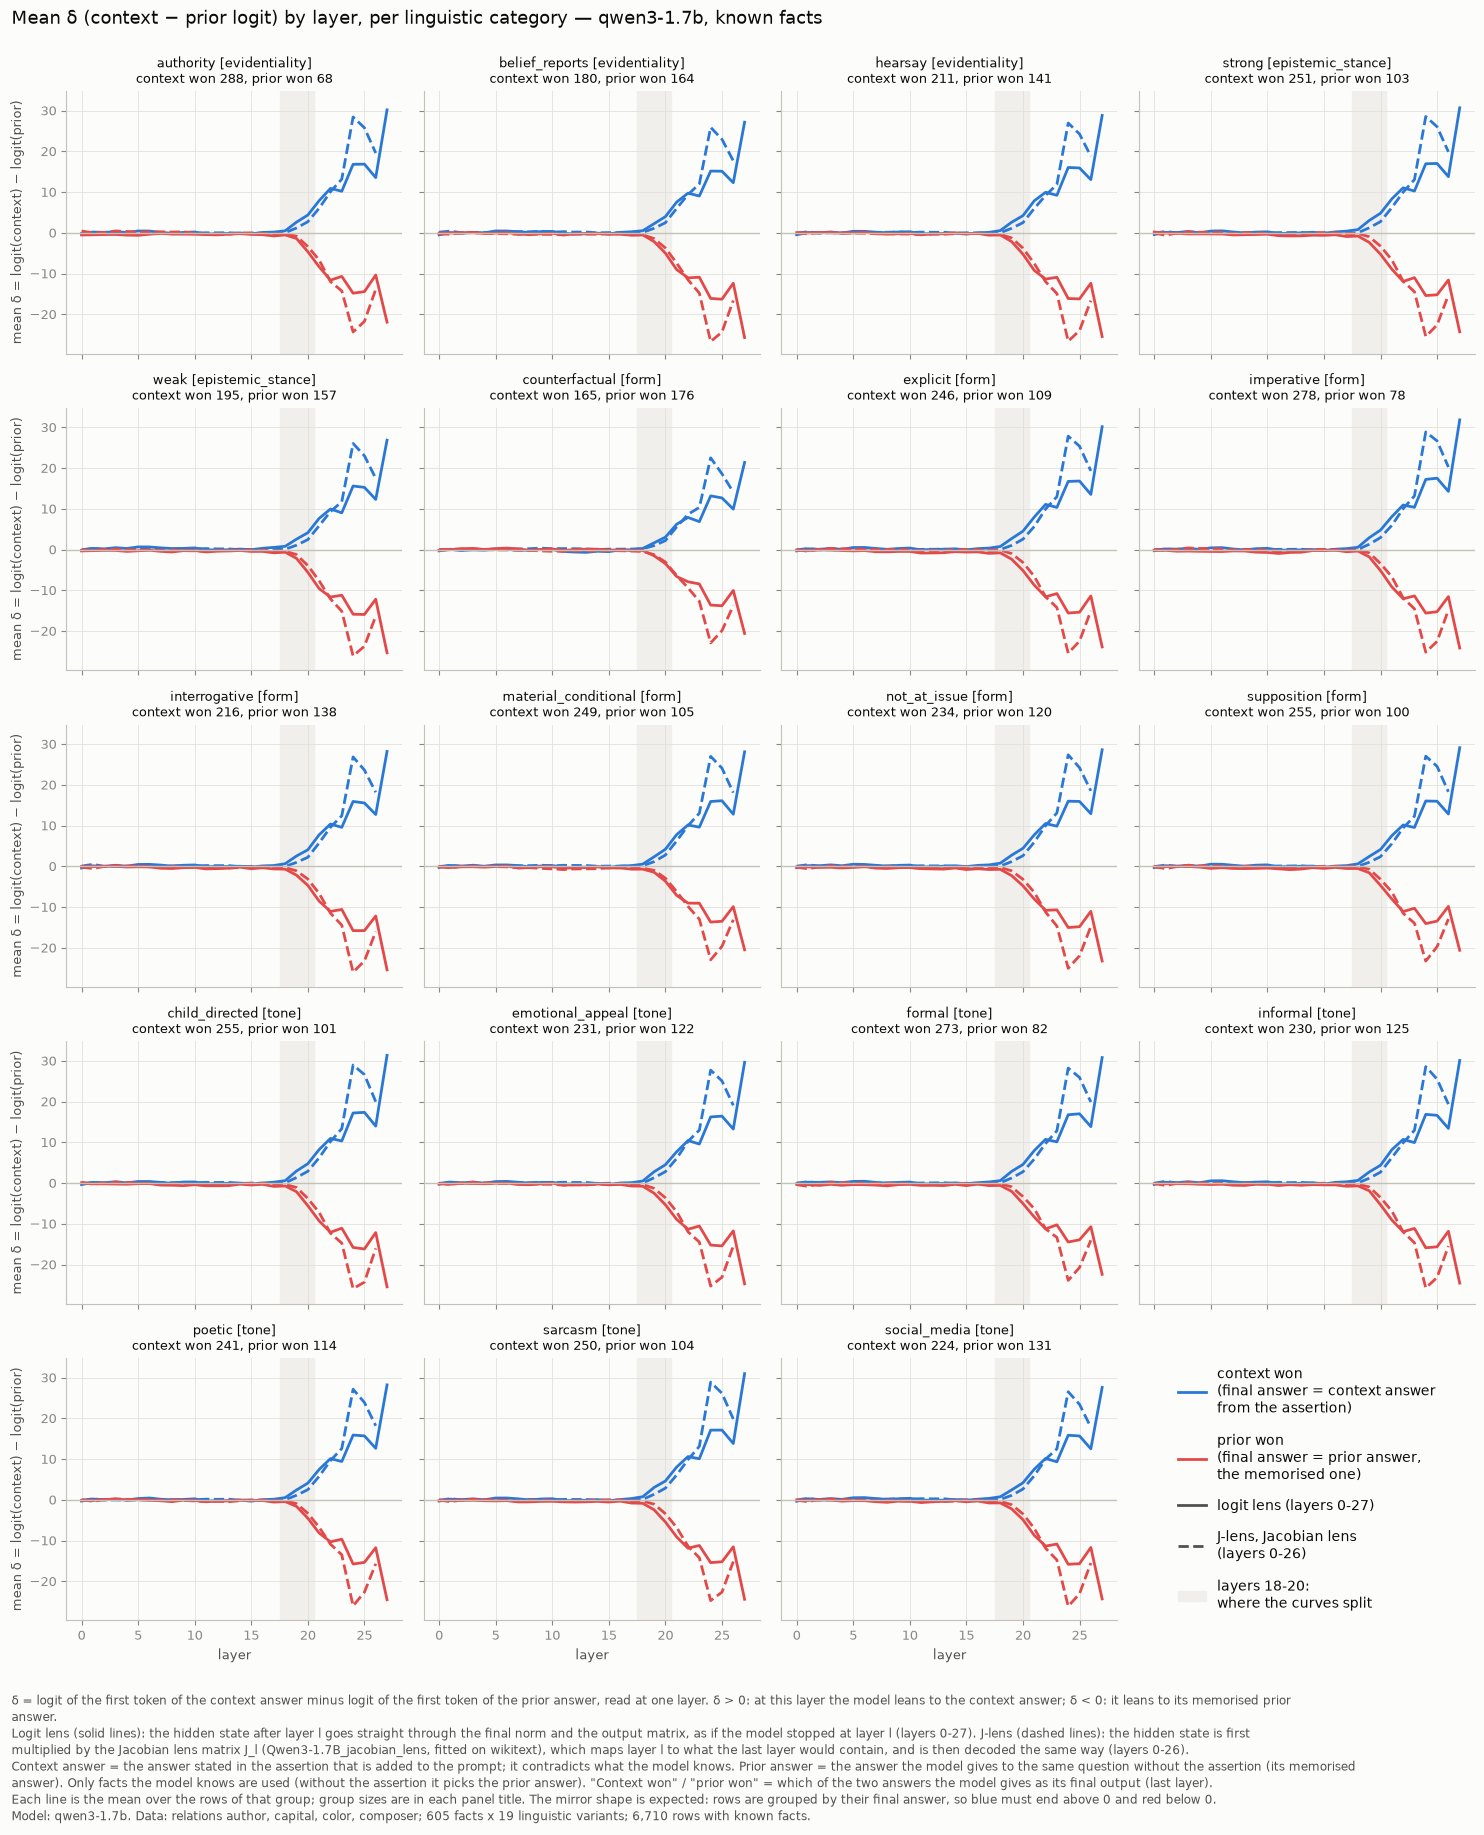

In [3]:
def lens_grid(Y_ll, Y_jl, title, fname, ylabel, cap):
    fig, axes = plt.subplots(5, 4, figsize=(15, 17), sharex=True, sharey=True)
    axes = axes.ravel()
    for ax, (dim, cat) in zip(axes, CATS):
        m = (df.dimension == dim).values & (df.category == cat).values
        for won, col in [(True, CTX), (False, PRI)]:
            s = m & (is_ctx == won)
            ax.plot(X_LL, Y_ll[s].mean(0), color=col, lw=2)
            ax.plot(X_JL, Y_jl[s].mean(0), color=col, lw=2, ls='--')
        ax.axhline(0, color=BASE, lw=1)
        ax.axvspan(17.5, 20.5, color='#f0efec', zorder=0)
        ax.set_title(f'{cat} [{dim}]\ncontext won {(m & is_ctx).sum()}, prior won {(m & ~is_ctx).sum()}', fontsize=9)
    for ax in axes[len(CATS):]:
        ax.axis('off')
    handles = [Line2D([], [], color=CTX, lw=2, label='context won\n(final answer = context answer\nfrom the assertion)'),
               Line2D([], [], color=PRI, lw=2, label='prior won\n(final answer = prior answer,\nthe memorised one)'),
               Line2D([], [], color=INK2, lw=2, label='logit lens (layers 0-27)'),
               Line2D([], [], color=INK2, lw=2, ls='--', label='J-lens, Jacobian lens\n(layers 0-26)'),
               mpl.patches.Patch(color='#f0efec', label='layers 18-20:\nwhere the curves split')]
    axes[len(CATS)].legend(handles=handles, loc='center', fontsize=10, labelspacing=1.1)
    for ax in axes[16:]: ax.set_xlabel('layer')
    for ax in axes[::4]: ax.set_ylabel(ylabel)
    fig.suptitle(title, x=0.01, ha='left', fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.98))
    caption(fig, *cap)
    fig.savefig(OUT / fname, dpi=130)
    return fig

FIG2 = lens_grid(LL, JL, 'Mean δ (context − prior logit) by layer, per linguistic category — qwen3-1.7b, known facts',
                 'fig2_lens_curves.png', 'mean δ = logit(context) − logit(prior)',
                 [DELTA_T, LENS_T, TERMS, 'Each line is the mean over the rows of that group; group sizes are in each panel title. '
                  'The mirror shape is expected: rows are grouped by their final answer, so blue must end above 0 and red below 0.', DATA_T])
plt.show()


## 3. What the assertion itself does: shift against the prompt without the assertion

Same panels, but y = $\delta_{\text{with assertion}} - \delta_{\text{without assertion}}$. This removes what the model would do on the bare question and shows only the push of the assertion. Above 0 = the assertion pushes toward the context answer at that layer.

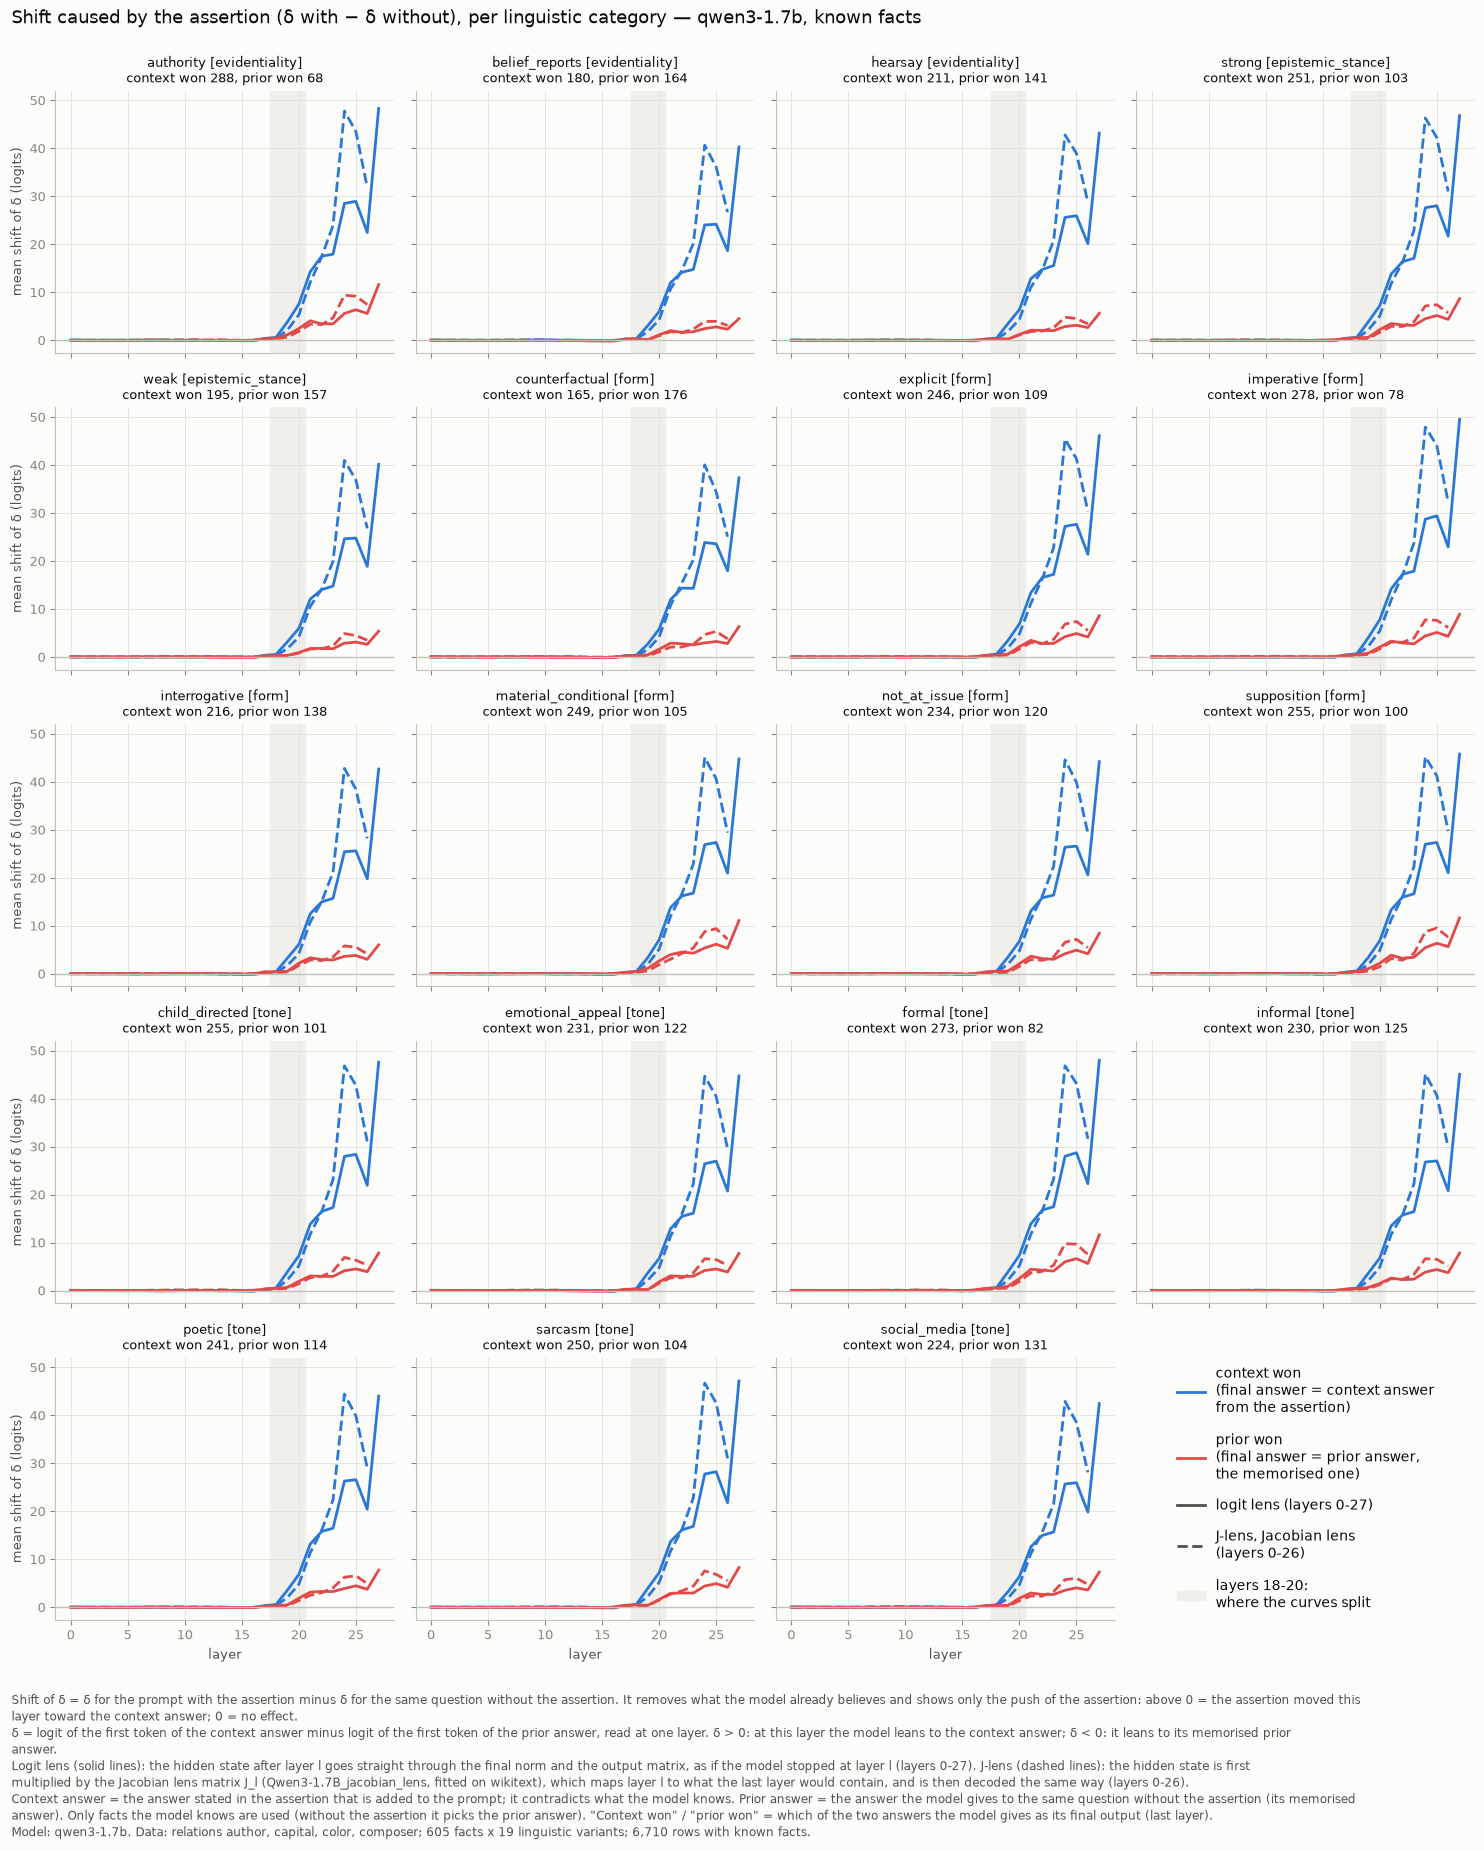

In [4]:
FIG3 = lens_grid(LL - LL0, JL - JL0,
                 'Shift caused by the assertion (δ with − δ without), per linguistic category — qwen3-1.7b, known facts',
                 'fig3_assertion_shift.png', 'mean shift of δ (logits)',
                 ['Shift of δ = δ for the prompt with the assertion minus δ for the same question without the assertion. '
                  'It removes what the model already believes and shows only the push of the assertion: '
                  'above 0 = the assertion moved this layer toward the context answer; 0 = no effect.', DELTA_T, LENS_T, TERMS, DATA_T])
plt.show()


## 4. Exactly which layers: layer-by-layer heatmap (J-lens)

Rows = linguistic categories, columns = layers, colour = mean shift caused by the assertion (J-lens). Left: rows where context won; right: rows where prior won. Same colour scale for both.

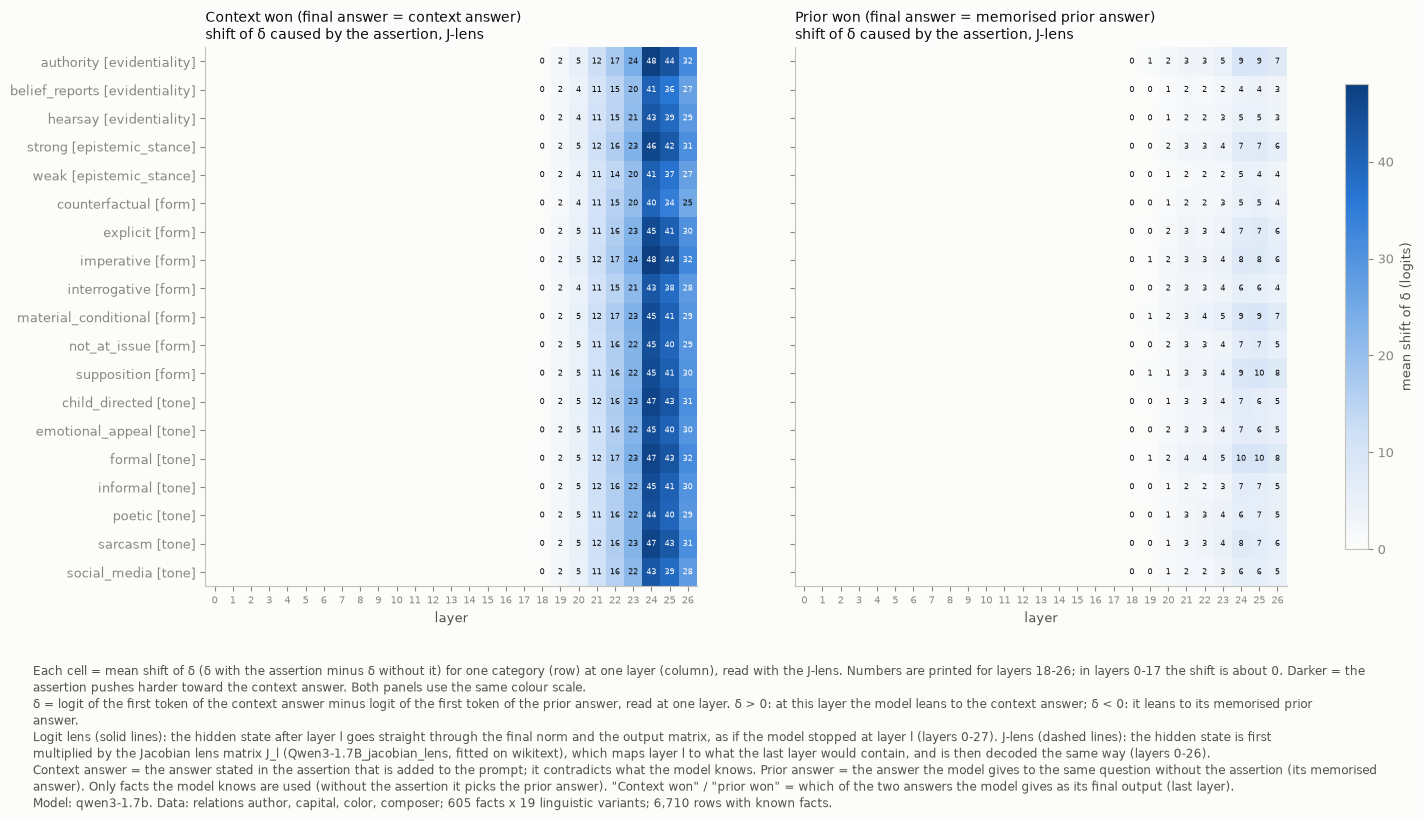

In [5]:
def cat_layer_matrix(Y, won):
    M = []
    for dim, cat in CATS:
        s = (df.dimension == dim).values & (df.category == cat).values & (is_ctx == won)
        M.append(Y[s].mean(0))
    return np.array(M)

S = JL - JL0
Mc, Mp = cat_layer_matrix(S, True), cat_layer_matrix(S, False)
vmax = np.ceil(max(Mc.max(), Mp.max()))
cmap = mpl.colors.LinearSegmentedColormap.from_list('seq_blue', ['#fcfcfb', '#cfe0f6', '#7aaee8', '#2a78d6', '#0d3f80'])
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
for ax, M, ttl in [(axes[0], Mc, 'Context won (final answer = context answer)'), (axes[1], Mp, 'Prior won (final answer = memorised prior answer)')]:
    im = ax.imshow(M, aspect='auto', cmap=cmap, vmin=0, vmax=vmax)
    ax.set_xticks(range(len(X_JL)), X_JL, fontsize=7); ax.set_xlabel('layer'); ax.grid(False)
    ax.set_title(f'{ttl}\nshift of δ caused by the assertion, J-lens', loc='left')
    for i in range(M.shape[0]):
        for j in range(18, M.shape[1]):
            ax.text(j, i, f'{M[i, j]:.0f}', ha='center', va='center', fontsize=6,
                    color='white' if M[i, j] > vmax * 0.55 else INK)
axes[0].set_yticks(range(len(CATS)), [f'{c} [{d}]' for d, c in CATS])
fig.colorbar(im, ax=axes, fraction=0.02, label='mean shift of δ (logits)')
caption(fig, 'Each cell = mean shift of δ (δ with the assertion minus δ without it) for one category (row) at one layer (column), read with the J-lens. '
        'Numbers are printed for layers 18-26; in layers 0-17 the shift is about 0. Darker = the assertion pushes harder toward the context answer. Both panels use the same colour scale.',
        DELTA_T, LENS_T, TERMS, DATA_T, y=0.0)
fig.savefig(OUT / 'fig4_heatmap_jlens.png', dpi=150, bbox_inches='tight'); FIG4 = fig; plt.show()


## 5. Where the change happens: distribution of the key layers

Pooled over all categories. Flip layer is shown for rows where context won (for prior-won rows the curve mostly never turns positive). Peak prior layer is shown for prior-won rows.

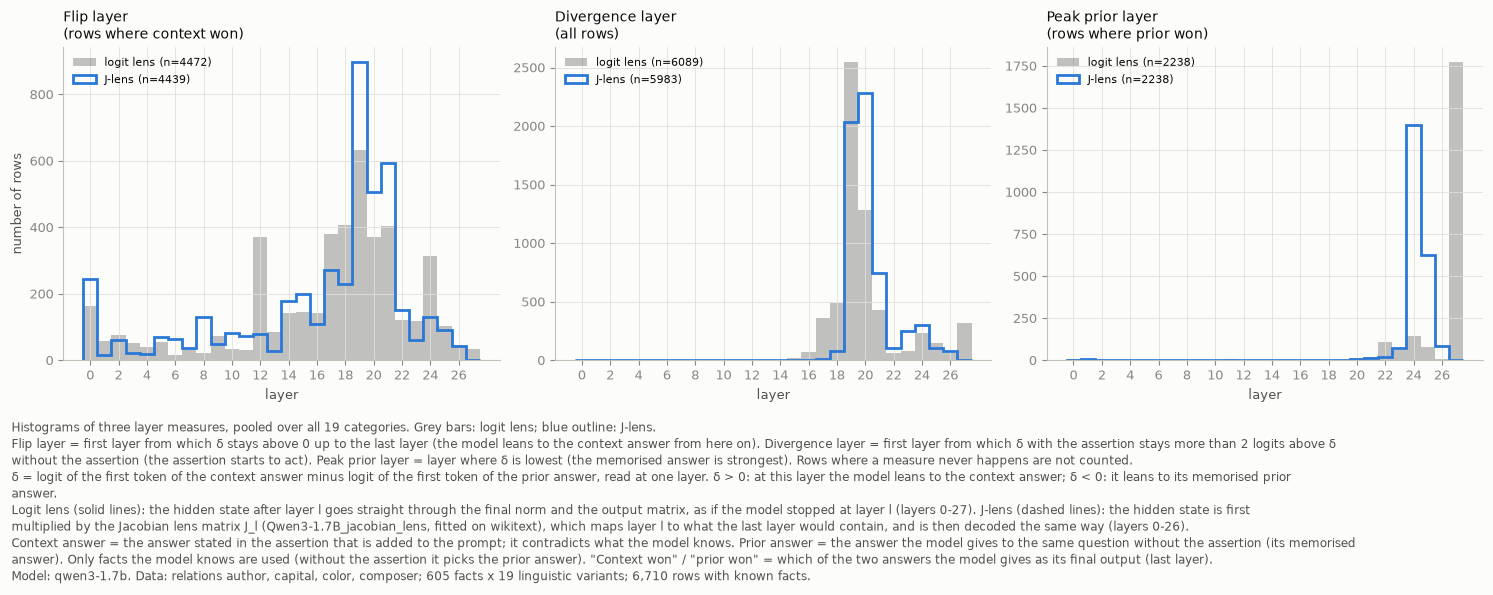

flip_logit_lens        n= 4472  median=18.0  IQR=14-21  missing=0.0%
flip_jlens             n= 4439  median=19.0  IQR=14-20  missing=0.7%
divergence_ll          n= 6089  median=19.0  IQR=19-20  missing=9.3%
divergence_jl          n= 5983  median=20.0  IQR=19-21  missing=10.8%
peak_prior_layer_ll    n= 2238  median=27.0  IQR=27-27  missing=0.0%
peak_prior_layer_jl    n= 2238  median=24.0  IQR=24-25  missing=0.0%


In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
bins = np.arange(-0.5, 28.5, 1)
panels = [
    ('Flip layer\n(rows where context won)', 'flip_logit_lens', 'flip_jlens', is_ctx),
    ('Divergence layer\n(all rows)', 'divergence_ll', 'divergence_jl', np.ones(len(df), bool)),
    ('Peak prior layer\n(rows where prior won)', 'peak_prior_layer_ll', 'peak_prior_layer_jl', ~is_ctx),
]
for ax, (ttl, cl, cj, m) in zip(axes, panels):
    a, b = df.loc[m, cl].dropna(), df.loc[m, cj].dropna()
    ax.hist(a, bins=bins, color=INK2, alpha=0.35, label=f'logit lens (n={len(a)})')
    ax.hist(b, bins=bins, histtype='step', color=CTX, lw=2, label=f'J-lens (n={len(b)})')
    ax.set_title(ttl, loc='left'); ax.set_xlabel('layer'); ax.set_xticks(range(0, 28, 2)); ax.legend(fontsize=8)
axes[0].set_ylabel('number of rows')
fig.tight_layout()
caption(fig, 'Histograms of three layer measures, pooled over all 19 categories. Grey bars: logit lens; blue outline: J-lens.',
        'Flip layer = first layer from which δ stays above 0 up to the last layer (the model leans to the context answer from here on). '
        'Divergence layer = first layer from which δ with the assertion stays more than 2 logits above δ without the assertion (the assertion starts to act). '
        'Peak prior layer = layer where δ is lowest (the memorised answer is strongest). Rows where a measure never happens are not counted.',
        DELTA_T, LENS_T, TERMS, DATA_T)
fig.savefig(OUT / 'fig5_layer_distributions.png', dpi=150); FIG5 = fig; plt.show()

for ttl, cl, cj, m in panels:
    for c in (cl, cj):
        v = df.loc[m, c].dropna()
        print(f'{c:22s} n={len(v):5d}  median={v.median():4.1f}  IQR={v.quantile(.25):.0f}-{v.quantile(.75):.0f}  missing={df.loc[m, c].isna().mean():.1%}')


## 6. Key layers per linguistic category (mean ± 95% CI)

Small differences between categories show up only in the means, because all categories turn within a few layers of each other.

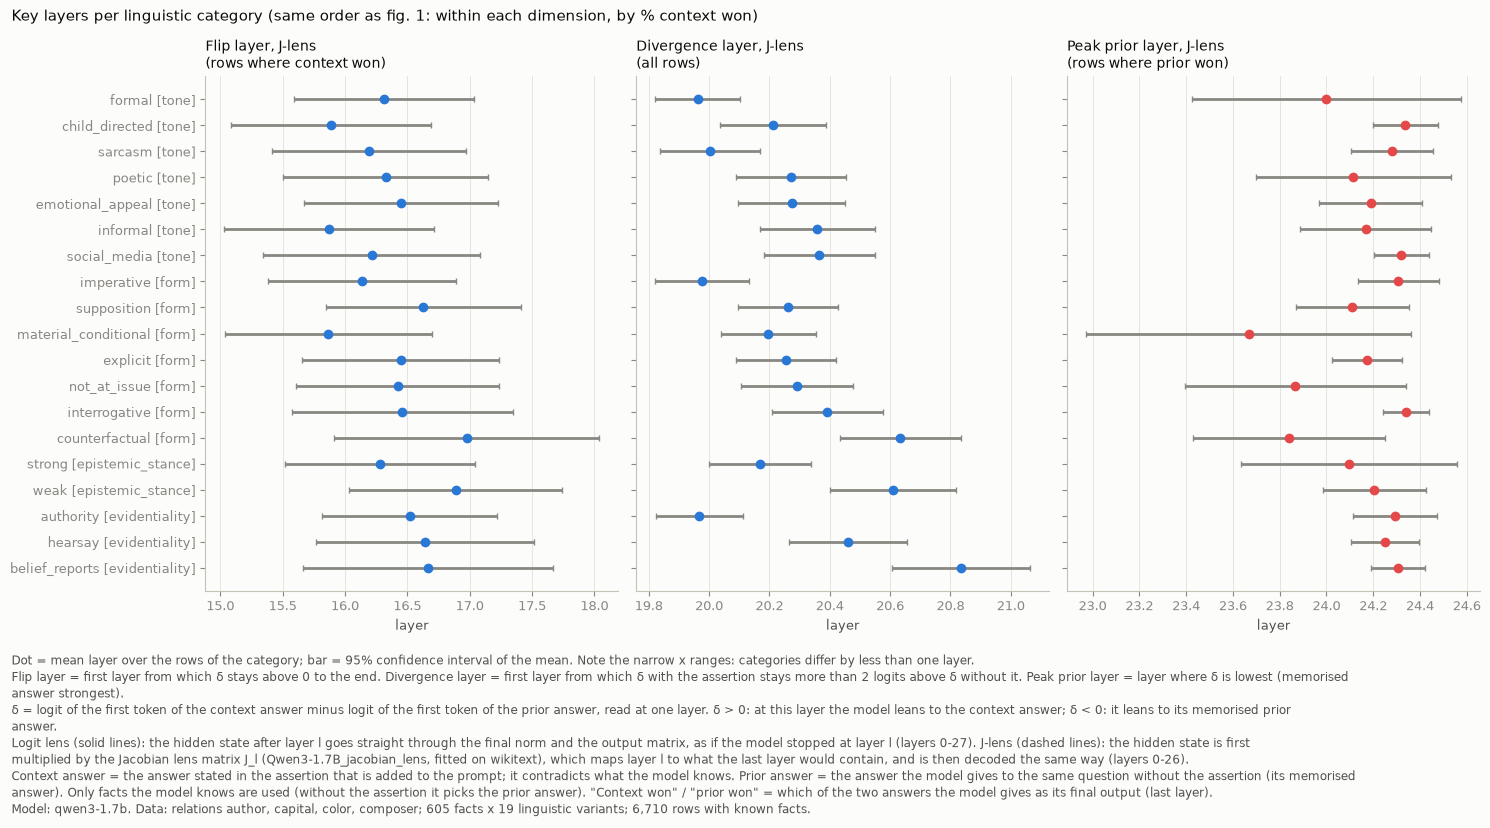

In [7]:
def mean_ci(v):
    v = v.dropna(); return v.mean(), 1.96 * v.std(ddof=1) / np.sqrt(len(v)) if len(v) > 1 else 0

metrics = [('Flip layer, J-lens\n(rows where context won)', 'flip_jlens', True),
           ('Divergence layer, J-lens\n(all rows)', 'divergence_jl', None),
           ('Peak prior layer, J-lens\n(rows where prior won)', 'peak_prior_layer_jl', False)]
order = beh[['dimension', 'category']].itertuples(index=False, name=None)  # sorted like fig. 1
order = list(order)
fig, axes = plt.subplots(1, 3, figsize=(15, 6.5), sharey=True)
y = np.arange(len(order))
for ax, (ttl, col, won) in zip(axes, metrics):
    for i, (dim, cat) in enumerate(order):
        m = (df.dimension == dim) & (df.category == cat)
        if won is not None: m &= (df.choice == 'context') == won
        mu, ci = mean_ci(df.loc[m, col])
        ax.errorbar(mu, i, xerr=ci, fmt='o', ms=6, color=CTX if won is not False else PRI, ecolor=MUTED, capsize=2)
    ax.set_title(ttl, loc='left'); ax.set_xlabel('layer'); ax.grid(axis='y', visible=False)
axes[0].set_yticks(y, [f'{c} [{d}]' for d, c in order])
fig.suptitle('Key layers per linguistic category (same order as fig. 1: within each dimension, by % context won)', x=0.01, ha='left')
fig.tight_layout()
caption(fig, 'Dot = mean layer over the rows of the category; bar = 95% confidence interval of the mean. Note the narrow x ranges: categories differ by less than one layer.',
        'Flip layer = first layer from which δ stays above 0 to the end. Divergence layer = first layer from which δ with the assertion stays more than 2 logits above δ without it. '
        'Peak prior layer = layer where δ is lowest (memorised answer strongest).', DELTA_T, LENS_T, TERMS, DATA_T)
fig.savefig(OUT / 'fig6_key_layers_by_category.png', dpi=150); FIG6 = fig; plt.show()


## 7. Summary table per category

In [8]:
rows = []
for dim, cat in order:
    m = (df.dimension == dim).values & (df.category == cat).values
    c, p = m & is_ctx, m & ~is_ctx
    rows.append({
        'dimension': dim, 'category': cat, 'n': m.sum(), 'context won %': 100 * c.sum() / m.sum(),
        'flip JL (ctx) mean': df.loc[c, 'flip_jlens'].mean(), 'flip LL (ctx) mean': df.loc[c, 'flip_logit_lens'].mean(),
        'divergence JL mean': df.loc[m, 'divergence_jl'].mean(),
        'peak prior JL (prior) mean': df.loc[p, 'peak_prior_layer_jl'].mean(),
        'shift JL L24 (ctx)': S[c, list(X_JL).index(24)].mean(), 'shift JL L24 (prior)': S[p, list(X_JL).index(24)].mean(),
        'δ final (ctx)': LL[c, -1].mean(), 'δ final (prior)': LL[p, -1].mean(),
    })
TAB = pd.DataFrame(rows).round(1)
TAB.to_csv(OUT / 'summary_by_category.csv', index=False)
TAB


,dimension,category,n,context won %,flip JL (ctx) mean,flip LL (ctx) mean,divergence JL mean,peak prior JL (prior) mean,shift JL L24 (ctx),shift JL L24 (prior),δ final (ctx),δ final (prior)
0,evidentiality,belief_reports,344,52.3,16.7,17.1,20.8,24.3,40.6,3.9,27.2,-25.7
1,evidentiality,hearsay,352,59.9,16.6,17.0,20.5,24.2,42.8,4.8,28.8,-25.5
2,evidentiality,authority,356,80.9,16.5,16.5,20.0,24.3,47.8,9.4,30.2,-21.9
3,epistemic_stance,weak,352,55.4,16.9,16.4,20.6,24.2,41.0,4.9,26.8,-25.3
4,epistemic_stance,strong,354,70.9,16.3,16.0,20.2,24.1,46.3,7.2,30.7,-24.3
5,form,counterfactual,341,48.4,17.0,17.8,20.6,23.8,40.0,4.7,21.4,-20.6
6,form,interrogative,354,61.0,16.5,16.8,20.4,24.3,42.8,5.8,28.2,-25.4
7,form,not_at_issue,354,66.1,16.4,16.7,20.3,23.9,44.6,6.6,28.6,-23.3
8,form,explicit,355,69.3,16.4,15.9,20.3,24.2,45.4,6.9,30.1,-23.9
9,form,material_conditional,354,70.3,15.9,16.5,20.2,23.7,45.1,8.8,28.1,-20.5


In [9]:
# separation layer: first layer where the mean curves of context-won and prior-won rows differ by > 2 logits
def first_sep(Y, x, thr=2.0):
    gap = Y[is_ctx].mean(0) - Y[~is_ctx].mean(0)
    idx = np.where(gap > thr)[0]
    return int(x[idx[0]]) if len(idx) else None
print('layer where context-won and prior-won curves separate by >2 logits: logit lens', first_sep(LL, X_LL), '| J-lens', first_sep(JL, X_JL))
print('mean assertion shift, layers 0-17 (all rows): logit lens %.2f, J-lens %.2f' % ((LL - LL0)[:, :18].mean(), S[:, :18].mean()))
for l in [17, 18, 19, 20, 21, 22, 24, 26]:
    j = list(X_JL).index(l)
    print(f'layer {l:2d}: J-lens shift context-won {S[is_ctx, j].mean():5.1f} | prior-won {S[~is_ctx, j].mean():5.1f}')


layer where context-won and prior-won curves separate by >2 logits: logit lens 19 | J-lens 19
mean assertion shift, layers 0-17 (all rows): logit lens 0.01, J-lens 0.02
layer 17: J-lens shift context-won   0.2 | prior-won   0.2
layer 18: J-lens shift context-won   0.3 | prior-won   0.3
layer 19: J-lens shift context-won   2.0 | prior-won   0.3
layer 20: J-lens shift context-won   4.8 | prior-won   1.4
layer 21: J-lens shift context-won  11.4 | prior-won   2.6
layer 22: J-lens shift context-won  16.0 | prior-won   2.6
layer 24: J-lens shift context-won  44.9 | prior-won   6.4
layer 26: J-lens shift context-won  29.7 | prior-won   5.1


## Findings

- **Data used:** qwen3-1.7b, 4 relations (author, capital, color, composer), known facts only: 6,710 rows (4,472 context won, 2,238 prior won). All 19 linguistic categories have 341–356 rows each.
- **Layers 0–17: no change.** Both lenses show mean δ near 0 for every category. The assertion shifts δ by only 0.01–0.02 logits on average there, so the early layers do not separate context from memory in a readable way.
- **Layers 18–20: the turn.** This is where the model's "decision" starts. The curves of context-won and prior-won rows first separate by more than 2 logits at layer 19 in both lenses. The median flip layer for context-won rows is 18 (logit lens) and 19 (J-lens). The median divergence layer, where the assertion moves the curve away from the bare question, is 19 (logit lens) and 20 (J-lens).
- **Layers 21–27: the decision grows.** In context-won rows the assertion pushes δ by about 11 logits at layer 21, 16 at layer 22 and 45 at layer 24 (J-lens). This is the strongest point; it falls back a little at layers 25–26. In prior-won rows the assertion still pushes toward the context, but only by about 3–6 logits, and the memorised answer is strongest around layer 24 (J-lens) or at the last layer (logit lens).
- **Logit lens vs J-lens:** both lenses give the same picture and the same turning layers. The J-lens is about 1 layer later at the start of the turn, and shows larger values at layers 24–25 than the logit lens.
- **Linguistic parameters change how often the context wins, not where the turn happens.** Context won from 48% (counterfactual) and 52% (belief_reports) up to 77% (formal), 78% (imperative) and 81% (authority). Across all 19 categories the turn sits in the same 18–21 layer window. The mean layers differ by less than 1 layer.
- **Still, the small layer differences follow behaviour.** Categories that win more often diverge earlier and push harder. Across the 19 categories, the correlation of % context won with the mean divergence layer is −0.93, and with the size of the J-lens shift at layer 24 it is +0.97 (context-won rows) and +0.90 (prior-won rows). Authority, imperative, formal and sarcasm diverge at about layer 20.0. Belief_reports (20.8), counterfactual (20.6), weak stance (20.6) and hearsay (20.5) diverge later and push less. Hedged or reported assertions start later and push less; direct, authoritative ones start earlier and push harder.
- **Per dimension:** evidentiality: authority > hearsay > belief_reports. Epistemic stance: strong > weak. Form: imperative highest, counterfactual lowest. Tone: formal highest, social_media lowest.
- **Caveats:** only 4 of 15 relations, so results may not hold for the whole dataset. The flip layer uses the first answer token only and has an early tail (IQR 14–21) where δ is near 0 and slightly positive by chance. The divergence layer is the more reliable layer measure. One model (1.7B) only.



In [10]:
REPORT_TEXT = ['Data used: qwen3-1.7b, 4 relations (author, capital, color, composer), known facts only: 6,710 rows (4,472 context won, 2,238 prior won). All 19 linguistic categories have 341–356 rows each.', 'Layers 0–17: no change. Both lenses show mean δ near 0 for every category. The assertion shifts δ by only 0.01–0.02 logits on average there, so the early layers do not separate context from memory in a readable way.', 'Layers 18–20: the turn. This is where the model\'s "decision" starts. The curves of context-won and prior-won rows first separate by more than 2 logits at layer 19 in both lenses. The median flip layer for context-won rows is 18 (logit lens) and 19 (J-lens). The median divergence layer, where the assertion moves the curve away from the bare question, is 19 (logit lens) and 20 (J-lens).', 'Layers 21–27: the decision grows. In context-won rows the assertion pushes δ by about 11 logits at layer 21, 16 at layer 22 and 45 at layer 24 (J-lens). This is the strongest point; it falls back a little at layers 25–26. In prior-won rows the assertion still pushes toward the context, but only by about 3–6 logits, and the memorised answer is strongest around layer 24 (J-lens) or at the last layer (logit lens).', 'Logit lens vs J-lens: both lenses give the same picture and the same turning layers. The J-lens is about 1 layer later at the start of the turn, and shows larger values at layers 24–25 than the logit lens.', 'Linguistic parameters change how often the context wins, not where the turn happens. Context won from 48% (counterfactual) and 52% (belief_reports) up to 77% (formal), 78% (imperative) and 81% (authority). Across all 19 categories the turn sits in the same 18–21 layer window. The mean layers differ by less than 1 layer.', 'Still, the small layer differences follow behaviour. Categories that win more often diverge earlier and push harder. Across the 19 categories, the correlation of % context won with the mean divergence layer is −0.93, and with the size of the J-lens shift at layer 24 it is +0.97 (context-won rows) and +0.90 (prior-won rows). Authority, imperative, formal and sarcasm diverge at about layer 20.0. Belief_reports (20.8), counterfactual (20.6), weak stance (20.6) and hearsay (20.5) diverge later and push less. Hedged or reported assertions start later and push less; direct, authoritative ones start earlier and push harder.', 'Per dimension: evidentiality: authority > hearsay > belief_reports. Epistemic stance: strong > weak. Form: imperative highest, counterfactual lowest. Tone: formal highest, social_media lowest.', 'Caveats: only 4 of 15 relations, so results may not hold for the whole dataset. The flip layer uses the first answer token only and has an early tail (IQR 14–21) where δ is near 0 and slightly positive by chance. The divergence layer is the more reliable layer measure. One model (1.7B) only.']
# PDF report: text page + all figures + summary table
from textwrap import wrap
def text_page(pdf, title, paragraphs):
    fig = plt.figure(figsize=(8.27, 11.69)); fig.text(0.07, 0.95, title, fontsize=15, weight='bold', va='top')
    yy = 0.91
    for p in paragraphs:
        for k, line in enumerate(wrap(p, 95) or ['']):
            fig.text(0.07, yy, line, fontsize=9.5, va='top'); yy -= 0.018
        yy -= 0.012
    pdf.savefig(fig); plt.close(fig)

with PdfPages(RES / 'qwen3-1.7b_lens_report.pdf') as pdf:
    text_page(pdf, 'qwen3-1.7b: where the model changes its mind', REPORT_TEXT)
    for f in [FIG1, FIG2, FIG3, FIG4, FIG5, FIG6]:
        pdf.savefig(f, bbox_inches='tight')
    fig, ax = plt.subplots(figsize=(16, 7)); ax.axis('off')
    t = ax.table(cellText=TAB.values, colLabels=['\n'.join(wrap(c, 14)) for c in TAB.columns], loc='center', cellLoc='center')
    t.auto_set_font_size(False); t.set_fontsize(7); t.scale(1, 1.5)
    for (r, c), cell in t.get_celld().items():
        if r == 0: cell.set_height(cell.get_height() * 2.2)
    ax.set_title('Summary per category (layers: means; shift and δ: logits)', loc='left')
    pdf.savefig(fig, bbox_inches='tight'); plt.close(fig)
print('saved', (RES / 'qwen3-1.7b_lens_report.pdf').relative_to(ROOT))


saved results/qwen3-1.7b/qwen3-1.7b_lens_report.pdf
